# Simulation study: can the methods recover a known causal effect?

**All data in this notebook is SYNTHETIC.** Real data can't tell us whether a method is right, because we never know the true effect. So we build a world where we *set* the true lift, add confounding, and see which estimators recover it.

**Data-generating process** (code: `src/simulate.py`)
- One confounder `X` (think "customer engagement") raises both the chance of being exposed *and* the chance of converting. That is selection bias.
- Baseline conversion 5%, true lift **+2pp** for everyone (so the true ATT is exactly 0.02), 50,000 users, ~30% exposed.
- Confounding strength: **none** (exposure is random), **moderate**, **strong**.
- **Estimand: ATT**, the effect on the people the campaign actually reached.

**Estimators** (code: `src/estimators.py`): naive exposed-vs-unexposed; a randomized-holdout benchmark; **IPW** (reweight unexposed users to look like the exposed); **PSM** (match each exposed user to a similar unexposed one).

**Assumptions:** SUTVA (no spillover between users), ignorability (given `X`, exposure is as good as random), overlap (every type of user could be exposed or not). They hold by construction here; the propensity model is also correctly specified, which is the best case, so real data will be harder.

In [1]:
import sys; sys.path.insert(0, '..')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme()

from src import power_analysis as pa, estimators as est
from src.simulate import simulate
from src.replicate import summarise

reps = pd.read_csv('../data/processed/sim_replications.csv')   # produced by: python -m src.run_sim
levels = ['none', 'moderate', 'strong']

## 1. Power analysis (planning, before collecting data)
How many users per arm are needed to detect a lift, given a 5% baseline, alpha = 0.05, power = 80%?

In [2]:
n = pa.required_n_per_arm(baseline=0.05, mde=0.02)
print(f'Detect 5% -> 7% (equal arms): {n:,.0f} users per arm')
for m in [0.005, 0.01, 0.02]:
    print(f'  MDE +{m*100:.1f}pp: {pa.required_n_per_arm(0.05, m):>10,.0f} per arm')
print()
# Real holdout design: 23,524 PSA (control) vs 564,577 ad users, i.e. ratio ~24:1
print('Smallest detectable lift in the real holdout design (baseline 5%):',
      f'{pa.min_detectable_lift(0.05, 23524, ratio=564577/23524)*100:.2f}pp')
print('Smallest detectable lift using the actual PSA baseline (1.79%):',
      f'{pa.min_detectable_lift(0.017854, 23524, ratio=564577/23524)*100:.2f}pp')

Detect 5% -> 7% (equal arms): 2,198 users per arm
  MDE +0.5pp:     31,217 per arm
  MDE +1.0pp:      8,143 per arm
  MDE +2.0pp:      2,198 per arm

Smallest detectable lift in the real holdout design (baseline 5%): 0.41pp


Smallest detectable lift using the actual PSA baseline (1.79%): 0.26pp


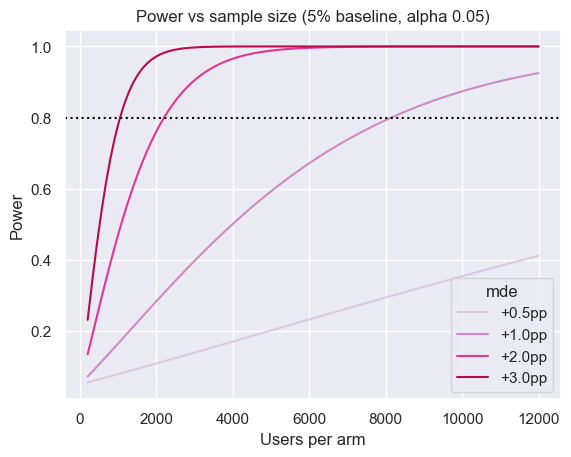

In [3]:
ns = np.linspace(200, 12_000, 100)
curves = pd.DataFrame([{'n': k, 'mde': f'+{m * 100:.1f}pp', 'power': pa.power_at(0.05, m, k)}
                       for m in [0.005, 0.01, 0.02, 0.03] for k in ns])

ax = sns.lineplot(data=curves, x='n', y='power', hue='mde', palette='PuRd')
ax.axhline(0.8, color='black', ls=':')
ax.set(xlabel='Users per arm', ylabel='Power', title='Power vs sample size (5% baseline, alpha 0.05)')
plt.savefig('../figures/power_curves.png', dpi=150, bbox_inches='tight')

Halving the MDE roughly **quadruples** the sample needed (n scales with 1/effect²).

## 2. Results: bias, RMSE and CI coverage over 500 replications per level
*Coverage for IPW and PSM uses bootstrap CIs on the first 100 replications per level (bootstrapping all 500 was too slow); naive and randomized use all 500.*

In [4]:
summary = summarise(reps)
summary.round(4)

,level,estimator,mean_est,bias,rmse,sd,coverage,n_ci_reps
0,none,naive,0.0199,-0.0001,0.0023,0.0023,0.954,500
1,none,randomized,0.0200,0.0000,0.0024,0.0024,0.948,500
2,none,ipw,0.0199,-0.0001,0.0023,0.0023,0.920,100
3,none,psm,0.0199,-0.0001,0.0031,0.0031,0.960,100
4,moderate,naive,0.0449,0.0249,0.0251,0.0026,0.000,500
5,moderate,randomized,0.0200,0.0000,0.0024,0.0024,0.948,500
6,moderate,ipw,0.0199,-0.0001,0.0031,0.0031,0.900,100
7,moderate,psm,0.0201,0.0001,0.0039,0.0039,0.990,100
8,strong,naive,0.0613,0.0413,0.0414,0.0026,0.000,500
9,strong,randomized,0.0200,0.0000,0.0024,0.0024,0.948,500


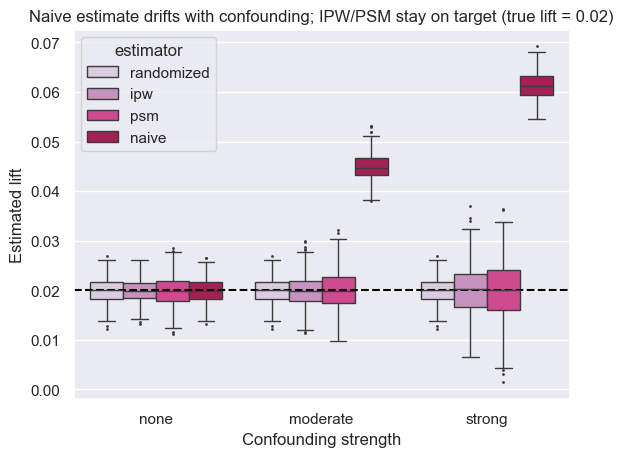

In [5]:
order = ['randomized', 'ipw', 'psm', 'naive']
long = reps.melt(id_vars='level', value_vars=order, var_name='estimator', value_name='estimate')

ax = sns.boxplot(data=long, x='level', y='estimate', hue='estimator', order=levels, hue_order=order,
                 palette='PuRd', fliersize=1)
ax.axhline(0.02, color='black', ls='--')
ax.set(xlabel='Confounding strength', ylabel='Estimated lift',
       title='Naive estimate drifts with confounding; IPW/PSM stay on target (true lift = 0.02)')
plt.savefig('../figures/estimates_by_confounding.png', dpi=150, bbox_inches='tight')

**Explanation:**
- **None:** with no confounding, even the naive estimator is fine, as is the randomized benchmark.
- **Moderate / strong:** the naive estimate is biased up (~+2.5pp and ~+4.1pp above the truth) and its CI **never** covers the true value (0% coverage), so it looks precise but is precisely wrong.
- **IPW and PSM** are essentially unbiased, but **noisier** as confounding grows (RMSE roughly doubles from none to strong), because adjustment throws away information. That is the price of removing the bias.
- The randomized benchmark is unbiased at every level, as expected.

## 3. Diagnostics

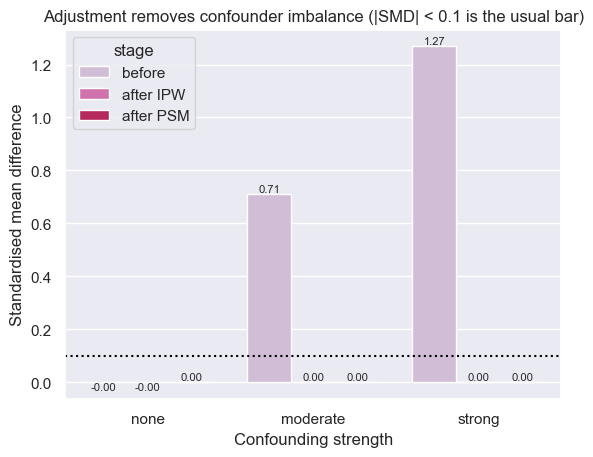

In [6]:
smd = (reps.groupby('level')[['smd_raw', 'smd_ipw', 'smd_psm']].mean().reindex(levels)
       .rename(columns={'smd_raw': 'before', 'smd_ipw': 'after IPW', 'smd_psm': 'after PSM'})
       .reset_index().melt(id_vars='level', var_name='stage', value_name='smd'))

ax = sns.barplot(data=smd, x='level', y='smd', hue='stage', palette='PuRd')
for bars in ax.containers:
    ax.bar_label(bars, fmt='%.2f', fontsize=8)
ax.axhline(0.1, color='black', ls=':')
ax.set(xlabel='Confounding strength', ylabel='Standardised mean difference',
       title='Adjustment removes confounder imbalance (|SMD| < 0.1 is the usual bar)')
plt.savefig('../figures/smd_balance.png', dpi=150, bbox_inches='tight')

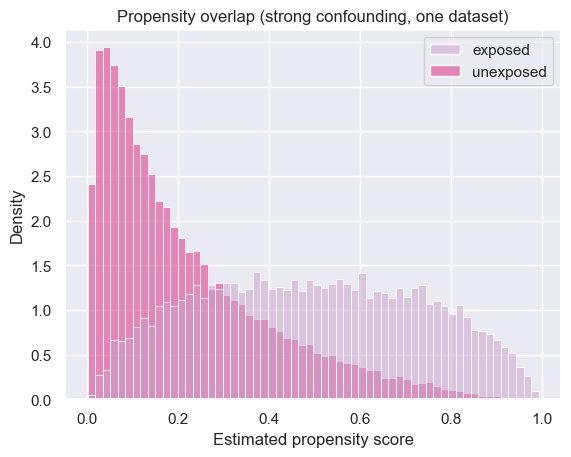

In [7]:
d = simulate(gamma=1.5, seed=3)          # one dataset, strong confounding
ps = est.fit_propensity(d.x, d.t)

ax = sns.histplot(x=ps, hue=np.where(d.t == 1, 'exposed', 'unexposed'), stat='density',
                  common_norm=False, bins=60, palette='PuRd')
ax.set(xlabel='Estimated propensity score', title='Propensity overlap (strong confounding, one dataset)')
plt.savefig('../figures/propensity_overlap.png', dpi=150, bbox_inches='tight')

Before adjustment the confounder is badly imbalanced (SMD ≈ 0.7 moderate, ≈ 1.3 strong); after IPW or matching it is ≈ 0. Overlap is adequate: exposed and unexposed users share common support, so reweighting and matching are possible. In the strong case some exposed users with extreme propensity have few comparable controls, so PSM drops a few (~24 per dataset on average).

### Placebo (negative-control) test
An outcome that depends on the confounder but is **not affected by exposure** (true effect = 0). A valid adjustment should find ≈ 0; the naive estimate finds a large false 'effect'.

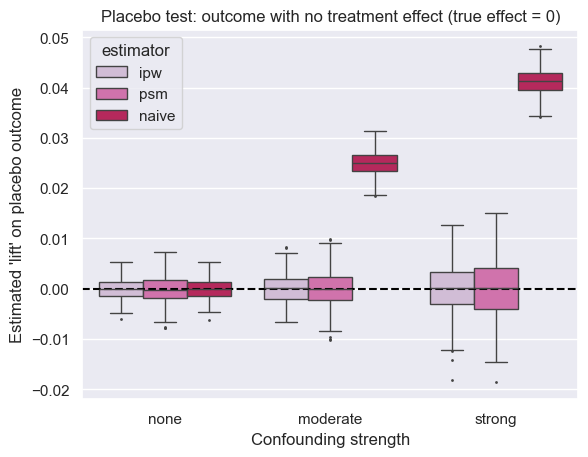

In [8]:
placebo = ['placebo_ipw', 'placebo_psm', 'placebo_naive']
long = (reps.melt(id_vars='level', value_vars=placebo, var_name='estimator', value_name='estimate')
        .replace({'placebo_ipw': 'ipw', 'placebo_psm': 'psm', 'placebo_naive': 'naive'}))

ax = sns.boxplot(data=long, x='level', y='estimate', hue='estimator', order=levels,
                 hue_order=['ipw', 'psm', 'naive'], palette='PuRd', fliersize=1)
ax.axhline(0, color='black', ls='--')
ax.set(xlabel='Confounding strength', ylabel="Estimated 'lift' on placebo outcome",
       title='Placebo test: outcome with no treatment effect (true effect = 0)')
plt.savefig('../figures/placebo.png', dpi=150, bbox_inches='tight')

## Limitations
- One observed confounder, correctly modeled. Real confounding is messier: unmeasured confounders can't be fixed by IPW/PSM at all.
- Constant treatment effect; real lift varies by user.
- IPW/PSM CI coverage is from 100 bootstrap replications per level, so those coverage figures are imprecise (± ~4–5pp).
- No spillover or interference between users (SUTVA assumed).